# Hälsostudie_Del 1
- I den här uppgiften undersöker jag data från en hälsostudie. Jag tittar bland annat på deltagarnas ålder, kön, längd, vikt, blodtryck, kolesterol och rökvanor.
- Jag använder Python för att räkna, göra grafer och undersöka om det finns skillnader mellan olika grupper.
- Datasetet finns i filen ../data/health_study_dataset.csv. Jag kör cellerna uppifrån och ned. Innan jag lämnar in kontrollerar jag att hela notebooken fungerar med Restart & Run All.

## 1. Importera bibliotek
Först importerar jag några bibliotek som jag behöver i uppgiften.
- pandas hjälper mig att läsa och arbeta med data i tabeller.
- numpy används för matematik och simuleringar.
- matplotlib används för att skapa grafer.
- scipy.stats innehåller funktioner för statistiska tester.
- Jag sätter också ett slumpfrö. Då blir simuleringarna likadana när jag kör koden igen.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42) 

## 2. Läsa in data
Sedan läser jag in CSV-filen med pandas. Sökvägen börjar med ../ eftersom notebooken ligger i mappen notebooks: Python går först upp till projektmappen och sedan in i mappen data. Ligger filerna någon annanstans får jag ändra sökvägen.

In [2]:
df = pd.read_csv("../data/health_study_dataset.csv")

df.head()


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## 3. Titta på datasetet
Innan jag börjar räkna vill jag se hur datan ser ut och vilka kolumner som finns.

- shape visar hur många rader och kolumner tabellen har.
- columns visar namnen på kolumnerna.
- info() visar vilken typ av data varje kolumn innehåller.
- isna().sum() räknar hur många värden som saknas i varje kolumn.
- Det hjälper mig att kontrollera att datan går att använda.

In [3]:
print("Antal rader och kolumner:", df.shape)
print("\nKolumnnamn:")
print(df.columns)

print("\nInformation om datasetet:")
df.info()


Antal rader och kolumner: (800, 9)

Kolumnnamn:
Index(['id', 'age', 'sex', 'height', 'weight', 'systolic_bp', 'cholesterol',
       'smoker', 'disease'],
      dtype='str')

Information om datasetet:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [4]:
print ("Saknade värden per kolumn:")
df.isna().sum()

Saknade värden per kolumn:


id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

## Kontrollera dubbletter och kategorier
Sedan kollar jag om någon rad finns flera gånger. Jag tittar också på vilka värden kolumnerna sex, smoker och disease innehåller, för att se hur kön, rökning och sjukdom är kodade.

In [5]:
print("Antal dubbelrader:", df.duplicated().sum())

print("\nFördelning av kön:")
print(df['sex'].value_counts())

print("\nFördelning av rökvanor:")
print(df['smoker'].value_counts())

print("\nFördelning av sjukdom (0 = nej, 1 = ja):")
print(df['disease'].value_counts())


Antal dubbelrader: 0

Fördelning av kön:
sex
F    403
M    397
Name: count, dtype: int64

Fördelning av rökvanor:
smoker
No     587
Yes    213
Name: count, dtype: int64

Fördelning av sjukdom (0 = nej, 1 = ja):
disease
0    753
1     47
Name: count, dtype: int64


## 4. Beskrivande statistik
Nu räknar jag ut några vanliga statistiska mått för ålder, vikt, längd, systoliskt blodtryck och kolesterol.
- Medelvärde är genomsnittet.
- Median är värdet i mitten när alla värden sorteras.
- Min är det lägsta värdet.
- Max är det högsta värdet.

Med dessa mått får jag en snabb överblick över deltagarnas värden.

In [6]:
koumner = ['age', 'weight', 'height', 'systolic_bp', 'cholesterol']

beskrivande_statistik = df[koumner].agg(["mean", "median", "min", "max"]) 

beskrivande_statistik.round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


## 5. Grafer
Jag gör tre grafer för att se hur värdena är fördelade och för att kunna jämföra grupper.

#### 5.1 Histogram över systoliskt blodtryck

Histogrammet visar hur blodtrycken fördelar sig. Staplarna räknar hur många deltagare som hamnar i varje intervall, så jag ser vilka värden som är vanligast och hur stor spridningen är.


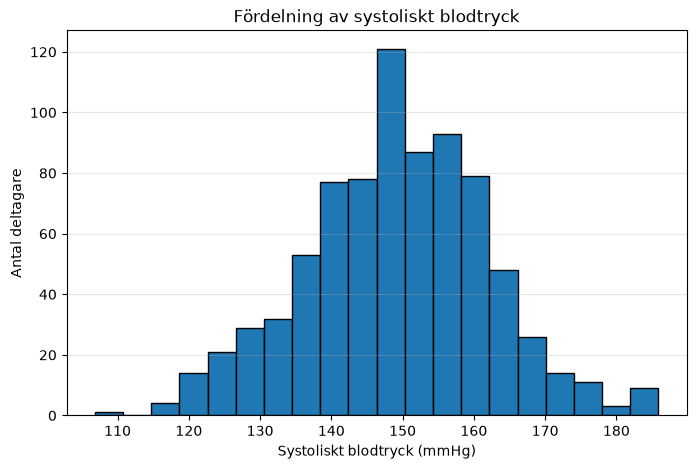

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(df["systolic_bp"], bins=20, edgecolor="black")
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.grid(axis="y", alpha=0.3)
plt.show()


#### 5.2 Boxplot över vikt per kön

Här jämför jag vikten mellan grupperna i kolumnen sex. Boxploten visar median och spridning och markerar värden som ligger långt från de övriga, så jag ser om viktfördelningen skiljer sig mellan grupperna.

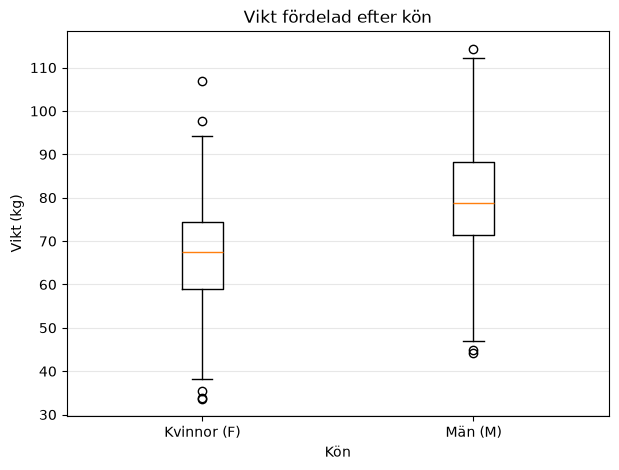

In [8]:
vikter_kvinnor = df.loc[df["sex"] == "F", "weight"]
vikter_man = df.loc[df["sex"] == "M", "weight"]

plt.figure(figsize=(7, 5))
plt.boxplot([vikter_kvinnor, vikter_man])
plt.xticks([1, 2], ["Kvinnor (F)", "Män (M)"])
plt.title("Vikt fördelad efter kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")
plt.grid(axis="y", alpha=0.3)
plt.show()



#### 5.3 Stapeldiagram över andelen rökare
Diagrammet visar hur stor andel av deltagarna som röker och hur stor andel som inte gör det. Med normalize=True blir staplarna andelar i stället för antal personer, vilket gör grupperna lättare att jämföra.

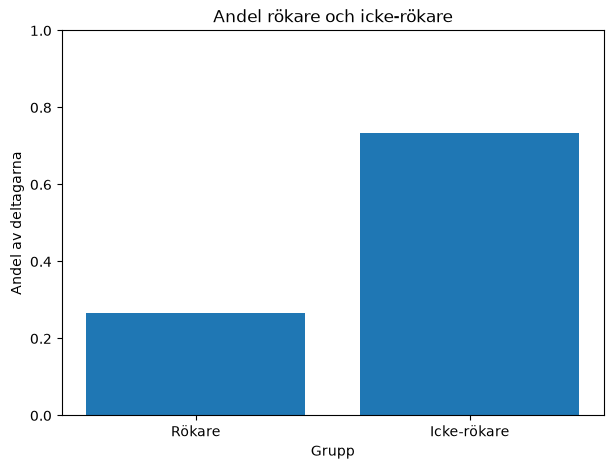

Andel rökare: 26.6 %
Andel icke-rökare: 73.4 %


In [9]:
andel_rokare = df["smoker"].value_counts(normalize=True).reindex(["Yes", "No"])

plt.figure(figsize=(7, 5))
plt.bar(["Rökare", "Icke-rökare"], andel_rokare.values)
plt.title("Andel rökare och icke-rökare")
plt.xlabel("Grupp")
plt.ylabel("Andel av deltagarna")
plt.ylim(0, 1)
plt.show()

print("Andel rökare:", round(andel_rokare["Yes"] * 100, 1), "%")
print("Andel icke-rökare:", round(andel_rokare["No"] * 100, 1), "%")
 

## 6. Sjukdomsförekomst och simulering
Först räknar jag ut hur stor andel av deltagarna som har sjukdomen.
I kolumnen disease betyder 1 att personen har sjukdomen och 0 att personen inte har den. Därför kan jag använda medelvärdet för att få fram andelen med sjukdomen.
Sedan simulerar jag 1 000 personer med samma sannolikhet för sjukdom. Varje simulerad person får värdet 1 eller 0:
- 1 betyder sjukdom.
- 0 betyder ingen sjukdom.

På så sätt kan jag jämföra resultatet från simuleringen med den riktiga andelen i datasetet.


In [10]:
andel_sjukdom = df["disease"].mean()

print("Verklig andel med sjukdom:", round(andel_sjukdom, 4))
print("Verklig andel i procent:", round(andel_sjukdom * 100, 2), "%")

simulerade_personer = np.random.binomial(n=1, p=andel_sjukdom, size=1000)

simulerad_andel = simulerade_personer.mean()

print("Simulerad andel:", round(simulerad_andel, 4))
print("Simulerad andel i procent:", round(simulerad_andel * 100, 2), "%")
print("Skillnad i procentenheter:", round((simulerad_andel - andel_sjukdom) * 100, 2), "%")

Verklig andel med sjukdom: 0.0588
Verklig andel i procent: 5.88 %
Simulerad andel: 0.056
Simulerad andel i procent: 5.6 %
Skillnad i procentenheter: -0.27 %


#### Vad visar simuleringen?
Den simulerade andelen behöver inte bli exakt samma som andelen i datasetet. Det beror på att simuleringen använder slumpmässiga resultat.
Om jag kör simuleringen igen får jag samma resultat eftersom jag har satt ett slumpfrö. Det gör det lättare att kontrollera och jämföra resultaten.

## 7. Konfidensintervall för medelvärdet av systoliskt blodtryck
Ett konfidensintervall visar ett intervall som hjälper oss att uppskatta populationens genomsnittliga blodtryck utifrån deltagarna i vårt dataset.
Jag räknar ett 95-procentigt konfidensintervall. Det betyder att metoden är gjord för att ge intervall som täcker det sanna medelvärdet i ungefär 95 procent av upprepade stickprov.

#### 7.1 Normalapproximation
Jag använder formeln:

$$
\bar{x} \pm 1,96 \cdot \frac{s}{\sqrt{n}}
$$

där:
* $\bar{x}$ = stickprovets medelvärde
* $s$ = stickprovets standardavvikelse
* $n$ = antal observationer (deltagare)
* $1,96$ = det kritiska *z*-värdet för ett tvåsidigt 95-procentigt konfidensintervall

Metoden använder medelvärdet och standardavvikelsen för att räkna ut intervallet.


In [11]:
blodtryck = df["systolic_bp"]

medel_blodtryck = blodtryck.mean()
standardavvikelse = blodtryck.std(ddof=1)
antal = blodtryck.count()
standardfel = standardavvikelse / np.sqrt(antal)

x_varde = 1.96
nedre_normalt = medel_blodtryck - x_varde * standardfel 
ovre_normalt = medel_blodtryck + x_varde * standardfel

print(f"Medelvärde: {medel_blodtryck:.2f} mmHg")
print(f"95% konfidensintervall (normalapproximation): {nedre_normalt:.2f} - {ovre_normalt:.2f}) mmHg")  

Medelvärde: 149.18 mmHg
95% konfidensintervall (normalapproximation): 148.29 - 150.07) mmHg


#### 7.2 Bootstrap-konfidensintervall
- Bootstrap är en annan metod för att räkna ut ett konfidensintervall.

- Datorn drar många nya stickprov från vårt dataset. Samma person kan väljas flera gånger eftersom urvalet görs med återläggning.

- För varje nytt stickprov räknar vi ut medelvärdet. Sedan använder vi de mittersta 95 procenten av resultaten för att skapa intervallet.

- I den här uppgiften gör jag 5 000 sådana stickprov.

In [12]:
rng = np.random.default_rng(42)  
antal_bootstrap = 5000
bootstrap_medel = []

for i in range(antal_bootstrap):
    nytt_stickprov = rng.choice(blodtryck, size=antal, replace=True)
    bootstrap_medel.append(nytt_stickprov.mean())
    
nedre_bootstrap = np.percentile(bootstrap_medel, 2.5)
ovre_bootstrap = np.percentile(bootstrap_medel, 97.5)

print(f"95% bootsdrap-konfidensintervall: ({nedre_bootstrap:.2f} - {ovre_bootstrap:.2f}) mmHg")

95% bootsdrap-konfidensintervall: (148.30 - 150.06) mmHg


#### Jämförelse av intervallen

Sedan jämför jag de två resultaten. Ligger gränserna nära varandra ger metoderna ungefär samma intervall för den här datan. Normalapproximationen bygger på en formel, medan bootstrap bygger på många nya stickprov ur datan, och det är därför det är värt att ställa dem mot varandra.

In [13]:
jamforelse_ci = pd.DataFrame({
    "Metod": ["Normalapproximation", "Bootstrap"],
    "Nedre gräns": [nedre_normalt, nedre_bootstrap],
    "Övre gräns": [ovre_normalt, ovre_bootstrap]
})

jamforelse_ci.round(2)


,Metod,Nedre gräns,Övre gräns
0,Normalapproximation,148.29,150.07
1,Bootstrap,148.30,150.06


## 8. Hypotesprövning: har rökare högre blodtryck?
Nu undersöker jag om rökare i vårt dataset har högre genomsnittligt systoliskt blodtryck än personer som inte röker.

Jag använder två hypoteser:
- Nollhypotes (H₀): Rökare har inte högre genomsnittligt blodtryck än icke-rökare.
- Mothypotes (H₁): Rökare har högre genomsnittligt blodtryck än icke-rökare.

Jag använder ett ensidigt Welch t-test för att jämföra gruppernas medelvärden. Testet fungerar även om grupperna har olika spridning i sina värden.
Signifikansnivån är 0,05, alltså 5 procent.

In [14]:
rokare = df.loc[df["smoker"] == "Yes", "systolic_bp"]
icke_rokare = df.loc[df["smoker"] == "No", "systolic_bp"]

print("Antal rökare:", len(rokare))
print("Antal icke-rökare:", len(icke_rokare))
print("Medelblodtryck rökare: {rokare.mean():.2f} mmHg")
print("Medelblodtryck icke-rökare: {icke_rokare.mean():.2f} mmHg")

testresultat = stats.ttest_ind(rokare, icke_rokare, equal_var=False, alternative='greater')

alpha = 0.05
print(f"t-statistik: {testresultat.statistic:.3f}")
print(f"p-värde: {testresultat.pvalue:.4f}")

if testresultat.pvalue < alpha:
    print("Resultatet: Förkasta nollhypotesen." )
else:
    print("Resultatet: Vi kan inte förkasta nollhypotesen.")   

Antal rökare: 213
Antal icke-rökare: 587
Medelblodtryck rökare: {rokare.mean():.2f} mmHg
Medelblodtryck icke-rökare: {icke_rokare.mean():.2f} mmHg
t-statistik: 0.450
p-värde: 0.3264
Resultatet: Vi kan inte förkasta nollhypotesen.


#### Hur tolkar jag hypotesprövningen?
Jag jämför p-värdet med 0,05.
- Om p-värdet är mindre än 0,05 förkastar jag nollhypotesen. Då finns det statistiskt stöd för att rökare har högre medelblodtryck.
- Om p-värdet är 0,05 eller större kan jag inte förkasta nollhypotesen. Då har jag inte tillräckligt statistiskt stöd för att säga att rökare har högre medelblodtryck.
 
Att jag inte kan förkasta nollhypotesen betyder inte att grupperna säkert är lika. Det betyder bara att testet inte visar tillräckligt starka bevis för en högre nivå hos rökare.
Testet visar inte heller att rökning orsakar ett högre blodtryck.

## 9. Simulering av testets styrka 
Styrka handlar om hur ofta ett statistiskt test hittar en skillnad när det faktiskt finns en skillnad.

Här gör jag en simulering för att undersöka detta:
1. Jag använder antal personer och standardavvikelse från de två grupperna.
2. Jag skapar nya simulerade blodtrycksvärden för rökare och icke-rökare.
3. Jag använder gruppernas medelvärden från datasetet.
4. Jag gör Welch t-test många gånger.
5. Jag räknar hur många test som får ett p-värde under 0,05.

Andelen test som hittar en statistiskt signifikant skillnad blir vår uppskattning av power.
Simuleringen bygger på antaganden, till exempel att värdena följer en normalfördelning. Därför ska resultatet ses som en uppskattning och inte som ett säkert besked om framtida studier.

In [15]:
rng_power = np.random.default_rng(123)
antal_simuleringar = 2000
signifikanta_test = 0

medel_rokare = rokare.mean()
medel_icke_rokare = icke_rokare.mean()
sd_rokare = rokare.std(ddof=1)
sd_icke_rokare = icke_rokare.std(ddof=1)
n_rokare = len(rokare)
n_icke_rokare = len(icke_rokare)

for i in range(antal_simuleringar):
    sim_rokare = rng_power.normal(
        loc=medel_rokare,
        scale=sd_rokare,
        size=n_rokare
    )
    sim_icke_rokare = rng_power.normal(
        loc=medel_icke_rokare,
        scale=sd_icke_rokare,
        size=n_icke_rokare
    )

    sim_test = stats.ttest_ind(
        sim_rokare,
        sim_icke_rokare,
        equal_var=False,
        alternative="greater"
    )

    if sim_test.pvalue < alpha:
        signifikanta_test += 1

power = signifikanta_test / antal_simuleringar

print("Antal simuleringar:", antal_simuleringar)
print("Antal signifikanta test:", signifikanta_test)
print(f"Uppskattad power: {power:.3f}")
print(f"Uppskattad power i procent: {power * 100:.1f} %")


Antal simuleringar: 2000
Antal signifikanta test: 222
Uppskattad power: 0.111
Uppskattad power i procent: 11.1 %


#### Vad visar power-simuleringen?
Hög power betyder att testet ofta hittar den skillnad som vi har lagt in i simuleringen. Låg power betyder att testet ofta missar den skillnaden.